<a href="https://colab.research.google.com/github/shubham0109/langgraph-learning/blob/main/LangGraph4_Conditional_Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [3]:
class AgentState(TypedDict):
  number1: int
  operation: str
  number2: int
  finalNumber: int

In [4]:
def adder(state: AgentState) -> AgentState:
  state['finalNumber'] = state['number1'] + state['number2']
  return state

def subtractor(state: AgentState) -> AgentState:
  state['finalNumber'] = state['number1'] - state['number2']
  return state

def decide_next_node(state: AgentState) -> AgentState:
  if state['operation'] == '+':
    return "addition_operation"
  elif state['operation'] == '-':
    return "subtraction_operation"

In [5]:
graph = StateGraph(AgentState)

graph.add_node("add_node", adder)
graph.add_node("subtract_node", subtractor)
graph.add_node("router", lambda state:state)

graph.add_edge(START, "router")

graph.add_conditional_edges(
    "router",
    decide_next_node,
    {
        # Edge: Node
        "addition_operation": "add_node",
        "subtraction_operation": "subtract_node"
    }
)

graph.add_edge("add_node", END)
graph.add_edge("subtract_node", END)

app = graph.compile()

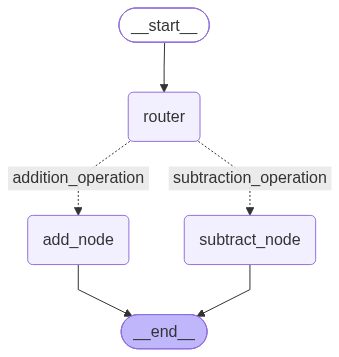

In [6]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [7]:
intial_state_1 = AgentState(number1 = 10, operation = "-", number2 = 5)
print(app.invoke(intial_state_1))

{'number1': 10, 'operation': '-', 'number2': 5, 'finalNumber': 5}


In [26]:
# Execrise
class AgentState1(TypedDict):
  number1: int
  operation1: str
  number2: int
  number3: int
  operation2: str
  number4: int
  finalNumber1: int
  finalNumber2: int

In [27]:
def adder(state: AgentState1) -> AgentState1:
  state['finalNumber1'] = state['number1'] + state['number2']
  return state

def subtractor(state: AgentState1) -> AgentState1:
  state['finalNumber1'] = state['number1'] - state['number2']
  return state

def decide_next_node(state: AgentState1) -> AgentState1:
  if state['operation1'] == '+':
    return "addition_operation1"
  elif state['operation1'] == '-':
    return "subtraction_operation1"

In [28]:
def adder2(state: AgentState1) -> AgentState1:
  state['finalNumber2'] = state['number3'] + state['number4']
  return state

def subtractor2(state: AgentState1) -> AgentState1:
  state['finalNumber2'] = state['number3'] - state['number4']
  return state

def decide_next_node2(state: AgentState1) -> AgentState1:
  if state['operation2'] == '+':
    return "addition_operation2"
  elif state['operation2'] == '-':
    return "subtraction_operation2"

In [29]:
graph2 = StateGraph(AgentState1)

graph2.add_node("add_node1", adder)
graph2.add_node("subtract_node1", subtractor)
graph2.add_node("router1", lambda state:state)
graph2.add_node("add_node2", adder2)
graph2.add_node("subtract_node2", subtractor2)
graph2.add_node("router2", lambda state:state)

graph2.add_edge(START, "router1")

graph2.add_conditional_edges(
    "router1",
    decide_next_node,
    {
        # Edge: Node
        "addition_operation1": "add_node1",
        "subtraction_operation1": "subtract_node1"
    }
)

graph2.add_edge("add_node1", "router2")
graph2.add_edge("subtract_node1", "router2")

graph2.add_conditional_edges(
    "router2",
    decide_next_node2,
    {
        # Edge: Node
        "addition_operation2": "add_node2",
        "subtraction_operation2": "subtract_node2"
    }
)

graph2.add_edge("add_node2", END)
graph2.add_edge("subtract_node2", END)

app = graph2.compile()

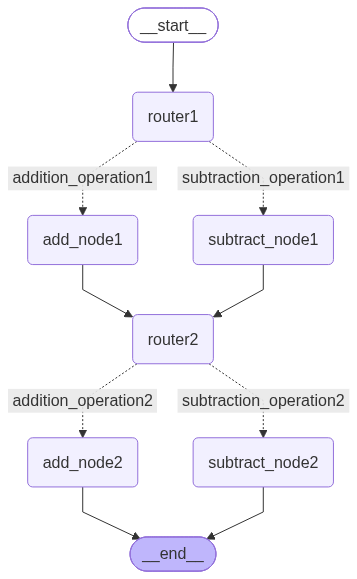

In [30]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [31]:
intial_state_2 = AgentState(number1 = 10, operation1 = "-", number2 = 5, number3 = 4, operation2 = "+", number4 = 6)
print(app.invoke(intial_state_2))

{'number1': 10, 'operation1': '-', 'number2': 5, 'number3': 4, 'operation2': '+', 'number4': 6, 'finalNumber1': 5, 'finalNumber2': 10}
